Дополнительное задание

1. Возьмите датасет на классификацию

2. Обучите модели линейной и логистической регрессий, а также деревья решений

3. Сравните их качество с помощью метрик классификаций (precision, f1,_score, recal, все в sklearn.metrics)

In [27]:
from sklearn.datasets import load_breast_cancer


data_cancer = load_breast_cancer()

X = data_cancer.data
y = data_cancer.target

print("X ->\n", X, "\ny -> \n", y)

X ->
 [[1.799e+01 1.038e+01 1.228e+02 ... 2.654e-01 4.601e-01 1.189e-01]
 [2.057e+01 1.777e+01 1.329e+02 ... 1.860e-01 2.750e-01 8.902e-02]
 [1.969e+01 2.125e+01 1.300e+02 ... 2.430e-01 3.613e-01 8.758e-02]
 ...
 [1.660e+01 2.808e+01 1.083e+02 ... 1.418e-01 2.218e-01 7.820e-02]
 [2.060e+01 2.933e+01 1.401e+02 ... 2.650e-01 4.087e-01 1.240e-01]
 [7.760e+00 2.454e+01 4.792e+01 ... 0.000e+00 2.871e-01 7.039e-02]] 
y -> 
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 1 0 1 1 1 1 1 0 0 1 0 0 1 1 1 1 0 1 0 0 1 1 1 1 0 1 0 0
 1 0 1 0 0 1 1 1 0 0 1 0 0 0 1 1 1 0 1 1 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 1 1
 1 1 1 1 1 1 0 0 0 1 0 0 1 1 1 0 0 1 0 1 0 0 1 0 0 1 1 0 1 1 0 1 1 1 1 0 1
 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 0 1 1 0 0 1 1 0 0 1 1 1 1 0 1 1 0 0 0 1 0
 1 0 1 1 1 0 1 1 0 0 1 0 0 0 0 1 0 0 0 1 0 1 0 1 1 0 1 0 0 0 0 1 1 0 0 1 1
 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 0 1 0 1 1 1 1 0 1 1 1 1 1 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 1 1 1 1 1 0 1 0 1 1 0 1 1 0 1 0 0 1 

In [28]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3)
print(f'''X_train shape: {X_train.shape}\nX_test shape: {X_test.shape}
y_train shape: {y_train.shape}\ny_test shape: {y_test.shape}\n''')

X_train shape: (398, 30)
X_test shape: (171, 30)
y_train shape: (398,)
y_test shape: (171,)



In [29]:
from sklearn.linear_model import LinearRegression

lin_elf = LinearRegression()
lin_elf.fit(X_train, y_train)
print(f'a: {lin_elf.coef_}')
print(f'b: {lin_elf.intercept_}')

a: [ 1.08122159e-01  3.17225668e-03 -1.17468000e-02 -2.08821436e-04
 -1.18701278e+00  3.00876620e+00 -1.24558485e+00 -1.00163434e+00
  2.79571353e-01  8.06378462e-01 -1.07598684e+00  2.77131355e-02
  8.48613954e-02  1.96184120e-03 -2.21341212e+01 -7.48941384e-01
  3.82797316e+00 -9.67688240e+00 -1.74930507e+00  1.73064561e+01
 -1.41637296e-01 -1.24620900e-02  5.59379068e-04  8.03190210e-04
  1.28238353e+00  1.68165205e-01 -5.34036235e-01 -1.10268537e+00
 -5.16616132e-01 -5.60660405e+00]
b: 2.8531254988223917


Score: 0.7488790027827323


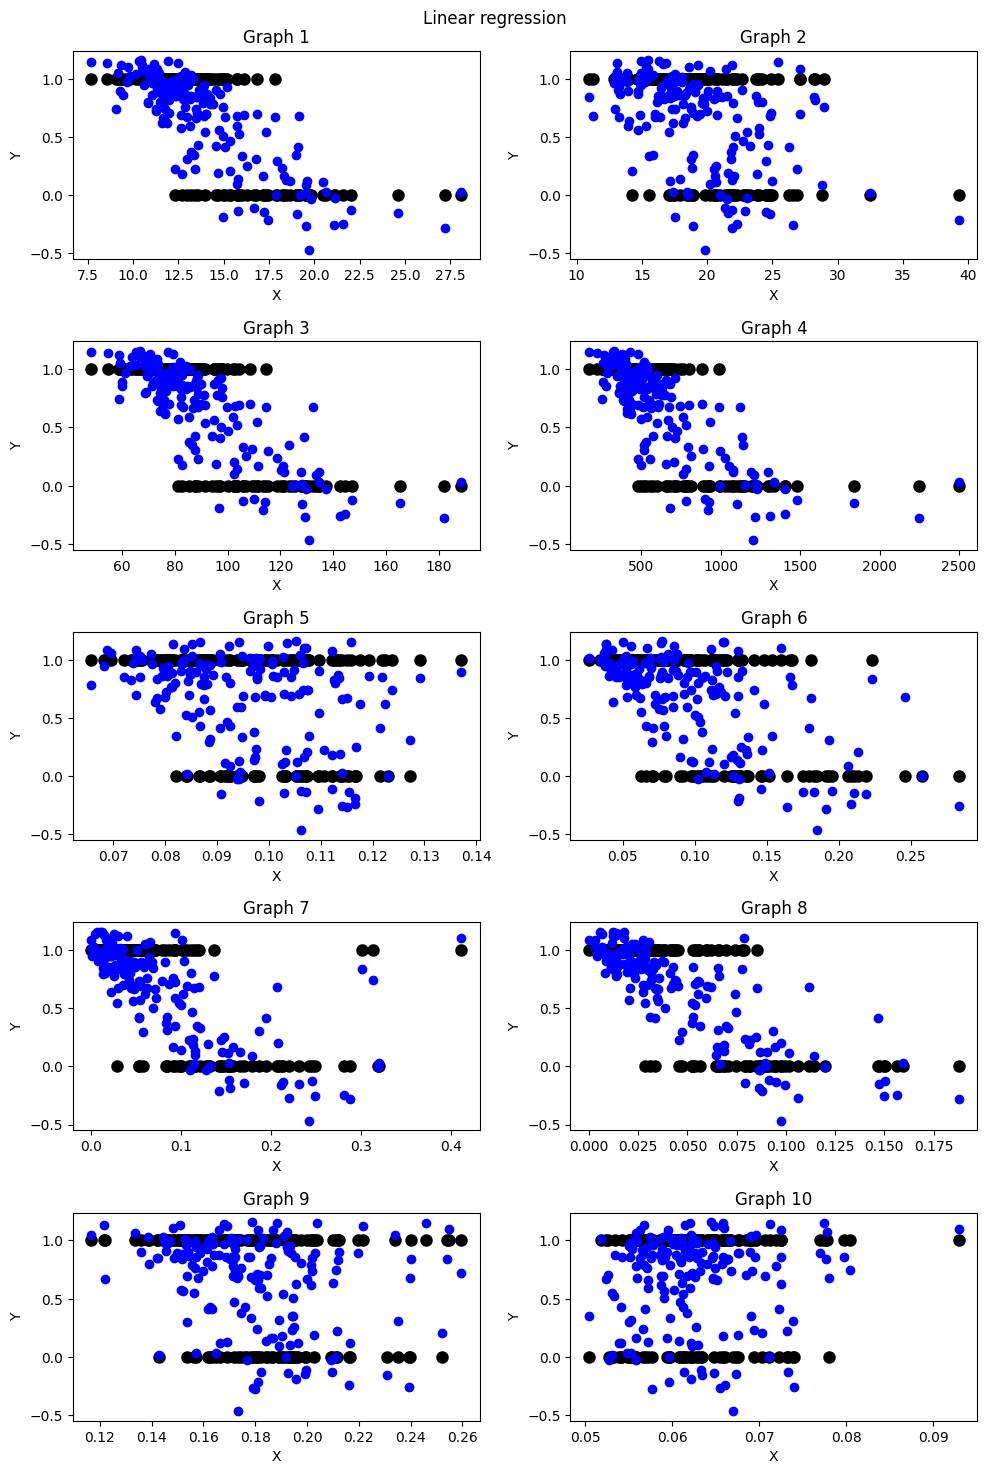

In [30]:
import matplotlib.pyplot as plt


y_pred = lin_elf.predict(X_test)
score = lin_elf.score(X_test, y_test)
print(f'Score: {score}')
i = 0

fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(10, 15))

axes_flat = axes.flatten()

fig.suptitle('Linear regression')
for i, ax in enumerate(axes_flat):
    ax.scatter(X_test[:, i], y_test, color='black', linewidths=3)
    ax.scatter(X_test[:, i], y_pred, color='blue')
    ax.set_ylabel('Y')
    ax.set_xlabel('X')
    ax.set_title(f'Graph {i+1}')

plt.tight_layout(pad = 1.12, h_pad=1.2)

plt.show()

Начинаем оценку для линейной регресии

In [31]:
import numpy as np


y_pred_class = np.rint(y_pred)
y_pred_class[y_pred_class > 1] = 1
y_pred_class[y_pred_class < 0] = 0
y_pred_class = y_pred_class.astype('int')
score = np.sum(y_pred_class == y_test) / len(y_test)
score

np.float64(0.9707602339181286)

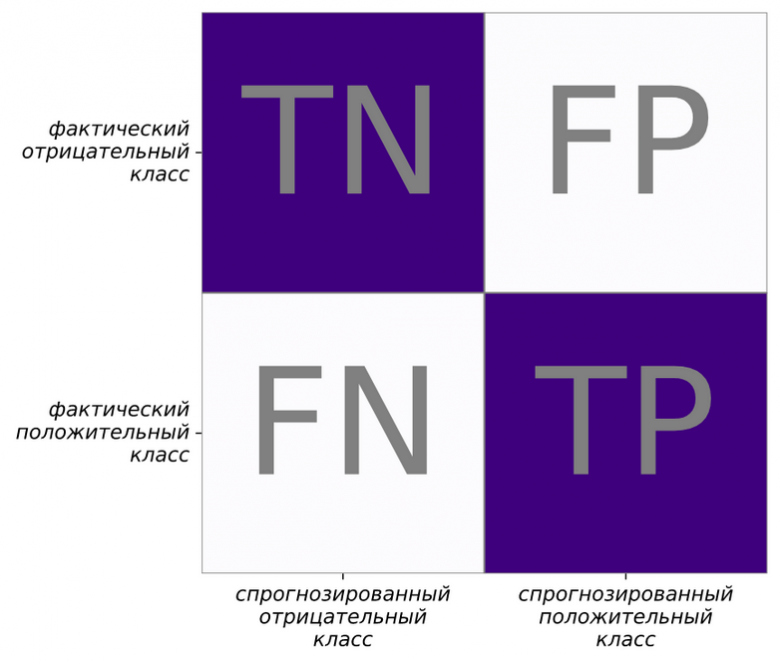

In [32]:
from sklearn.metrics import *


def get_all(model_name, y_pred, y_test):
    print(f'Оценка {model_name}')
    print(f'Accuracy: {accuracy_score(y_test, y_pred)}')
    print(f'Precision: {precision_score(y_test, y_pred)}')
    print(f'Recall: {recall_score(y_test, y_pred)}')
    print(f'f1: {f1_score(y_test, y_pred)}')
    if (model_name == 'Linear regression'):
        print(f'MSE: {mean_squared_error(y_test, y_pred)}')
        print(f'r2: {r2_score(y_test, y_pred)}')
        print(f'Mean absolute percentage Error: {mean_absolute_percentage_error(y_test, y_pred)}')
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix (Матрица ошибок):")
    print(f'{cm[0]} T-')
    print(f'{cm[1]} T+')
    print(' P-  P+')


get_all('Linear regression', y_pred_class, y_test)

Оценка Linear regression
Accuracy: 0.9707602339181286
Precision: 0.967479674796748
Recall: 0.9916666666666667
f1: 0.9794238683127572
MSE: 0.029239766081871343
r2: 0.8602941176470589
Mean absolute percentage Error: 105347359704573.0
Confusion Matrix (Матрица ошибок):
[47  4] T-
[  1 119] T+
 P-  P+


Score: 0.9532163742690059


d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


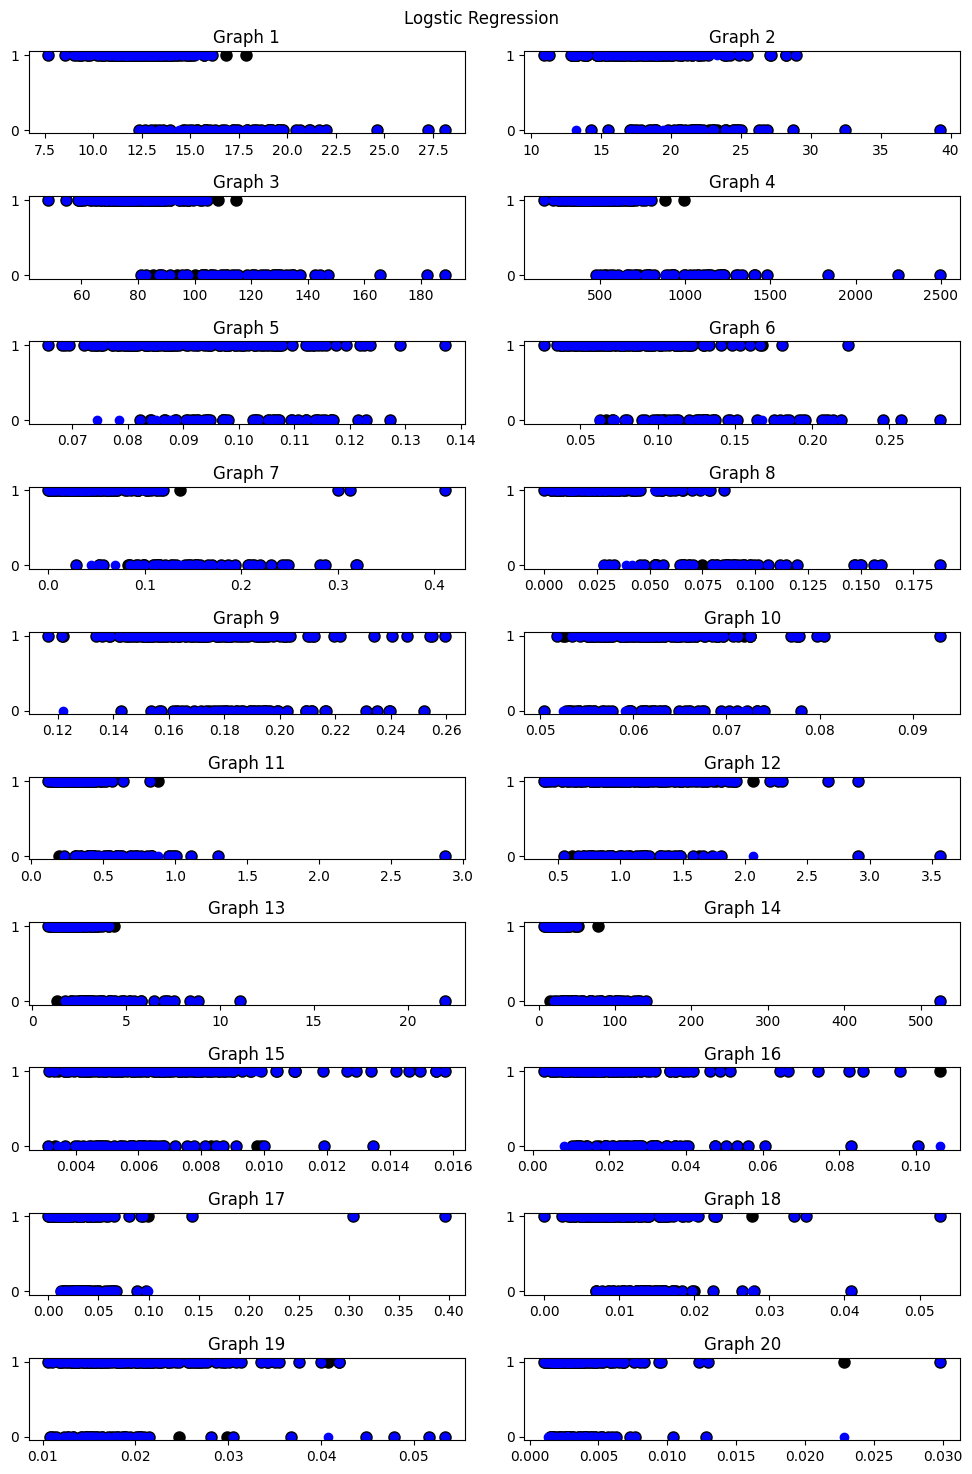

In [33]:
from sklearn.linear_model import LogisticRegression


log_reg = LogisticRegression(max_iter = 200)
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)
score = log_reg.score(X_test, y_test)

print(f'Score: {score}')
fig, axes = plt.subplots(ncols=2, nrows=10, figsize=(10, 15))

log_reg_flat = axes.flatten()

plt.suptitle('Logstic Regression')
for i, ax in enumerate(log_reg_flat):
    ax.scatter(X_test[:, i], y_test, color='black', linewidths=3)
    ax.scatter(X_test[:, i], y_pred, color='blue')
    ax.set_title(f'Graph {i+1}')

plt.tight_layout(pad = 1.12, h_pad=1.2)

plt.show()

Оценка Логистической регрессии

In [34]:
get_all("Logistic Regression", y_pred, y_test)

Оценка Logistic Regression
Accuracy: 0.9532163742690059
Precision: 0.9666666666666667
Recall: 0.9666666666666667
f1: 0.9666666666666667
Confusion Matrix (Матрица ошибок):
[47  4] T-
[  4 116] T+
 P-  P+


Score: 0.935672514619883
Оценка Tree classifier
Accuracy: 0.935672514619883
Precision: 0.990990990990991
Recall: 0.9166666666666666
f1: 0.9523809523809523
Confusion Matrix (Матрица ошибок):
[50  1] T-
[ 10 110] T+
 P-  P+


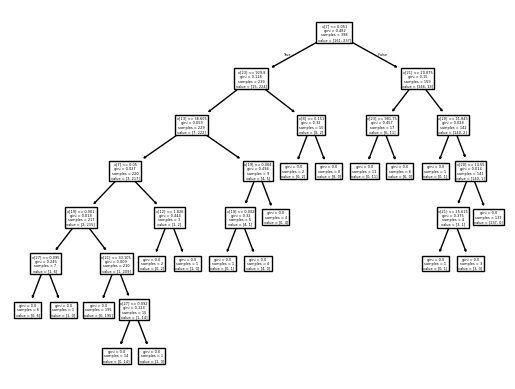

In [35]:
from sklearn import tree


tree_clf = tree.DecisionTreeClassifier(max_depth=10)
tree_clf.fit(X_train, y_train)
y_pred = tree_clf.predict(X_test)
tree.plot_tree(tree_clf)
score = tree_clf.score(X_test, y_test)
print(f'Score: {score}')
get_all('Tree classifier', y_pred, y_test)

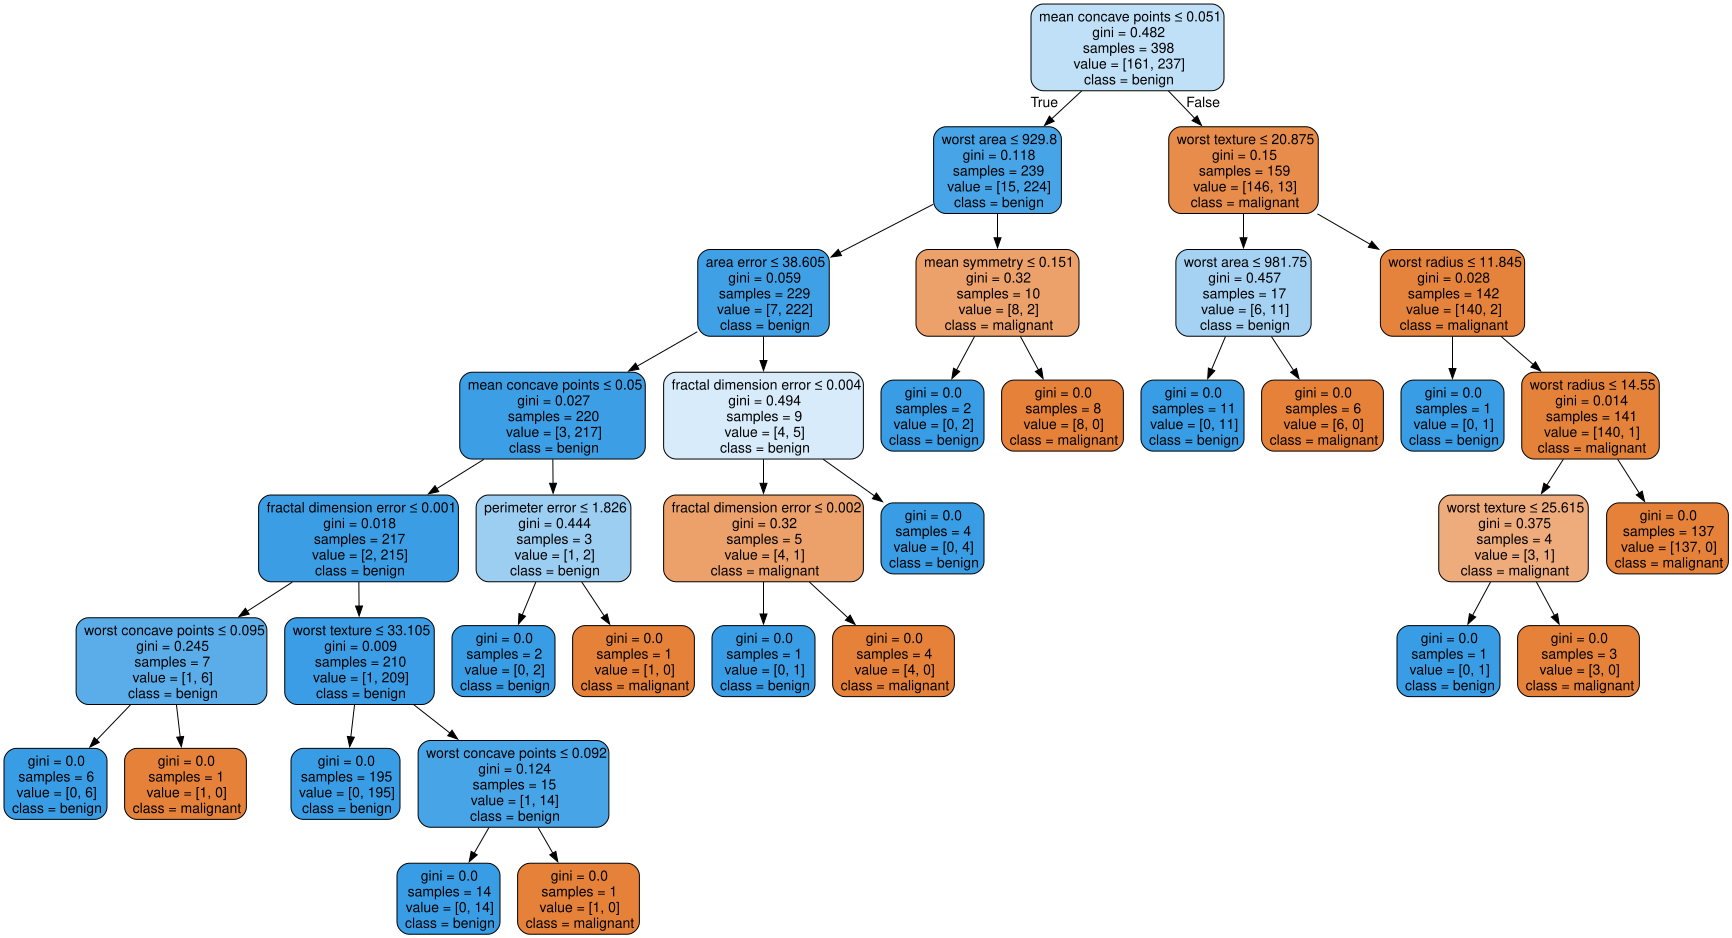

In [36]:
import graphviz


dot_data = tree.export_graphviz(tree_clf, out_file=None,
                                feature_names=data_cancer.feature_names,
                                class_names=data_cancer.target_names,
                                filled=True, rounded=True,
                                special_characters=True)
graph = graphviz.Source(dot_data)
graph

In [37]:
from sklearn.tree import export_text


r = export_text(tree_clf, feature_names=data_cancer.feature_names)
print(r)

|--- mean concave points <= 0.05
|   |--- worst area <= 929.80
|   |   |--- area error <= 38.60
|   |   |   |--- mean concave points <= 0.05
|   |   |   |   |--- fractal dimension error <= 0.00
|   |   |   |   |   |--- worst concave points <= 0.09
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- worst concave points >  0.09
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |--- fractal dimension error >  0.00
|   |   |   |   |   |--- worst texture <= 33.10
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- worst texture >  33.10
|   |   |   |   |   |   |--- worst concave points <= 0.09
|   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |--- worst concave points >  0.09
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |--- mean concave points >  0.05
|   |   |   |   |--- perimeter error <= 1.83
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- perimeter error >  1.83
|   |   |   |   |   |--- class: 0
|   |   |--- area error >  38.60

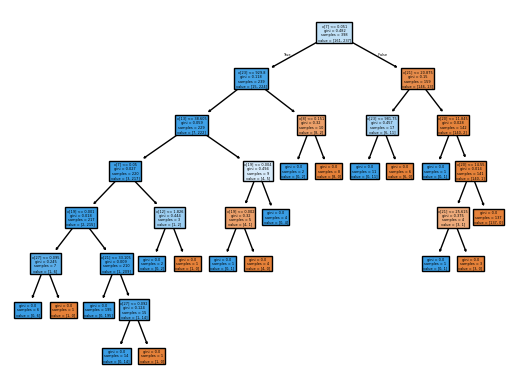

In [38]:
from sklearn.tree import plot_tree


plot_tree(tree_clf, filled=True)
plt.show()

[(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]


C:\Users\nuyki\AppData\Local\Temp\ipykernel_15772\2779154129.py:46: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(X_pair[idx, 0], X_pair[idx, 1], color=color,
C:\Users\nuyki\AppData\Local\Temp\ipykernel_15772\2779154129.py:46: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(X_pair[idx, 0], X_pair[idx, 1], color=color,
C:\Users\nuyki\AppData\Local\Temp\ipykernel_15772\2779154129.py:46: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(X_pair[idx, 0], X_pair[idx, 1], color=color,
C:\Users\nuyki\AppData\Local\Temp\ipykernel_15772\2779154129.py:46: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(X_pair[idx, 0], X_pair[idx, 1], color=color,
C:\Users\nuyki\AppData\Local\Temp\ipykernel_15772\2779154129.py:46: UserWarning: No data for colormapping provided via 'c'. Parameters '

(np.float64(-92.25),
 np.float64(2736.75),
 np.float64(0.04155300000000001),
 np.float64(0.174477))

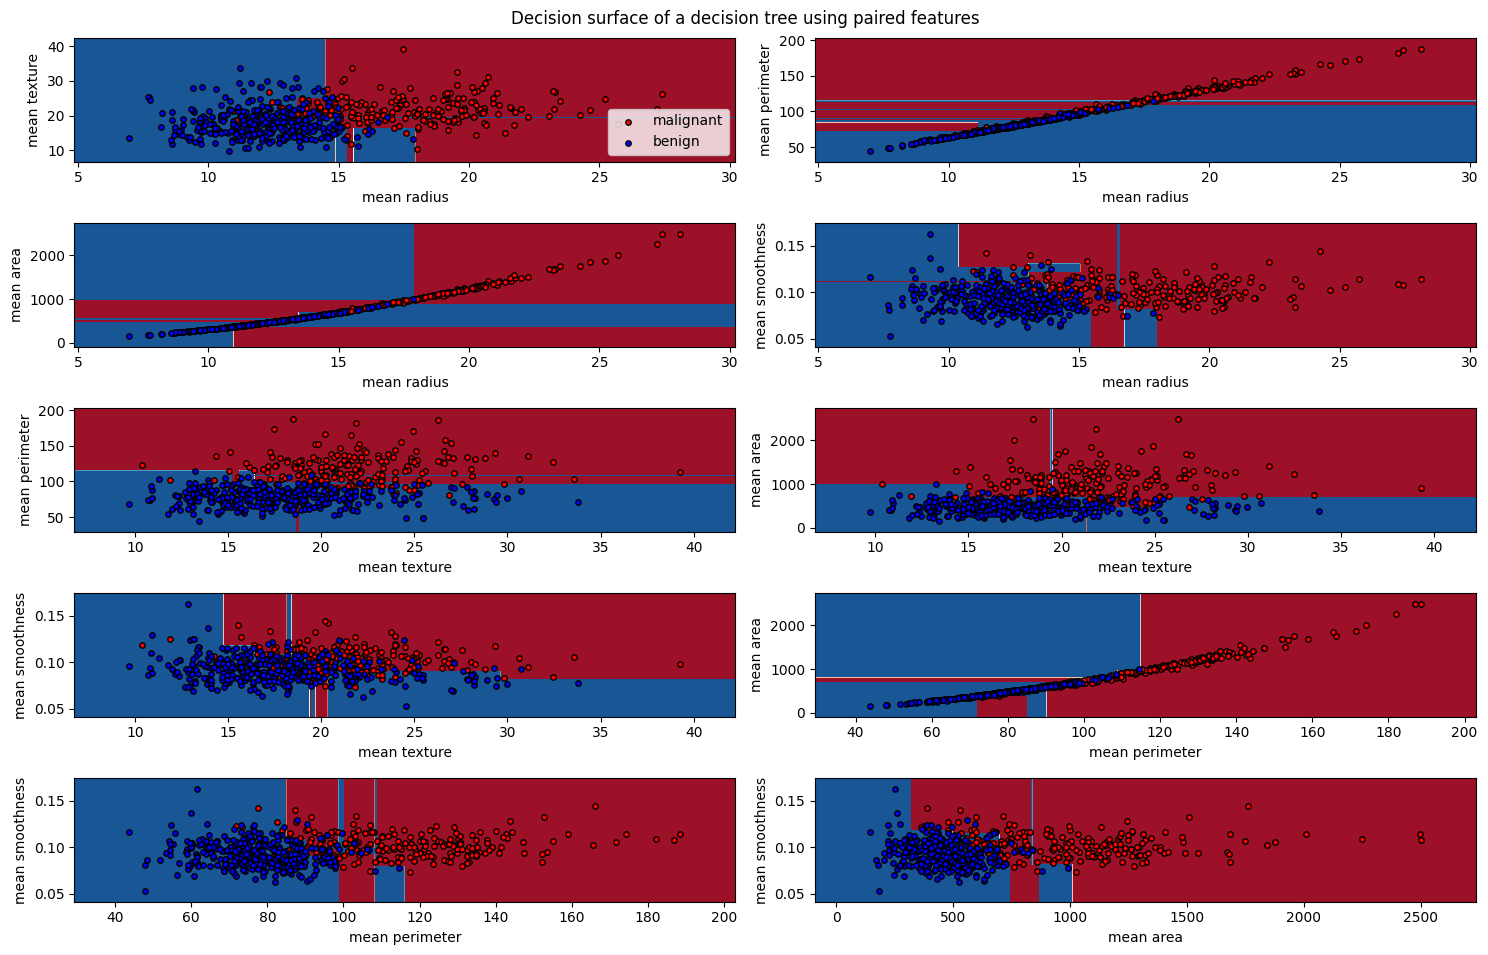

In [ ]:
from itertools import combinations


plot_colors = 'rb'
n_classes = 2
plot_step = .05
mx_depth = 5
all_comb = list(combinations([0, 1, 2, 3, 4], 2))
print(all_comb)

fig, axs = plt.subplots(nrows=5, ncols=2, figsize=(15, 10))

tree_flat = axs.flatten()

for i, ax in enumerate(tree_flat):
    pair = all_comb[i]
    X_pair = X[:, pair]

    clf = tree.DecisionTreeClassifier(max_depth=mx_depth).fit(X_pair, y)

    x_min, x_max = X_pair[:, 0].min(), X_pair[:, 0].max()
    y_min, y_max = X_pair[:, 1].min(), X_pair[:, 1].max()
    
    x_margin = (x_max - x_min) * 0.1
    y_margin = (y_max - y_min) * 0.1
    
    x_min -= x_margin
    x_max += x_margin
    y_min -= y_margin
    y_max += y_margin

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 1000),
                         np.linspace(y_min, y_max, 1000))
    
    
    y_pred = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    y_pred = y_pred.reshape(xx.shape)

    ax.contourf(xx, yy, y_pred, cmap=plt.cm.RdBu)

    ax.set_xlabel(data_cancer.feature_names[pair[0]])
    ax.set_ylabel(data_cancer.feature_names[pair[1]])

    for j, color in zip(range(n_classes), plot_colors):
        idx = np.where(y == j)
        ax.scatter(X_pair[idx, 0], X_pair[idx, 1], c=color,
                   label=data_cancer.target_names[j],
                   cmap=plt.cm.RdBu, edgecolor='black', s = 15)
        
plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.suptitle('Decision surface of a decision tree using paired features')
tree_flat[0].legend(loc='lower right')
plt.axis('tight')